# 2. Exploratory Revenue and Profitability Analysis
Explore trends, product/category economics, acquisition performance, and the conversion funnel.

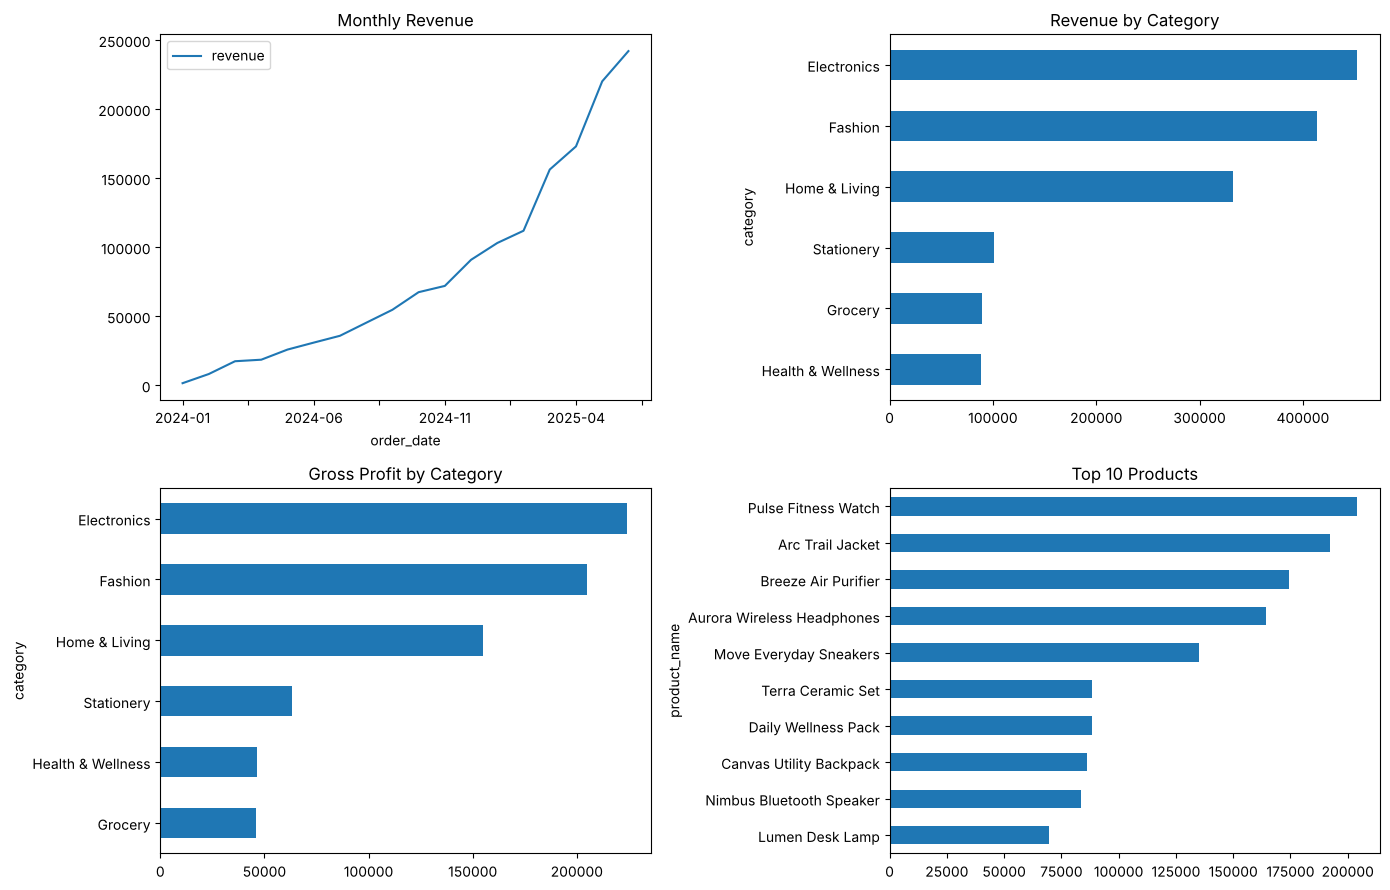

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
orders = pd.read_csv(ROOT / 'data' / 'processed' / 'orders_clean.csv', parse_dates=['order_date'])
completed = orders[orders.is_completed].copy()
monthly = completed.groupby(completed.order_date.dt.to_period('M').astype(str)).agg(revenue=('revenue','sum'), gross_profit=('gross_profit','sum'), orders=('order_id','nunique')).reset_index()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
monthly.plot(x='order_date', y='revenue', ax=axes[0,0], title='Monthly Revenue')
completed.groupby('category').revenue.sum().sort_values().plot.barh(ax=axes[0,1], title='Revenue by Category')
completed.groupby('category').gross_profit.sum().sort_values().plot.barh(ax=axes[1,0], title='Gross Profit by Category')
completed.groupby('product_name').revenue.sum().nlargest(10).sort_values().plot.barh(ax=axes[1,1], title='Top 10 Products')
plt.tight_layout(); plt.show()

In [2]:
funnel = pd.read_csv(ROOT / 'data' / 'processed' / 'funnel_clean.csv')
funnel[['website_sessions','product_views','add_to_cart','checkout_started','purchases']].sum()

website_sessions    336031
product_views       234888
add_to_cart          51052
checkout_started     32041
purchases            22272
dtype: int64